Running VisionPort Lifecycle Component Breakdown Benchmark...
Success! New component breakdown graph saved as 'visionport_lifecycle_breakdown.png'.


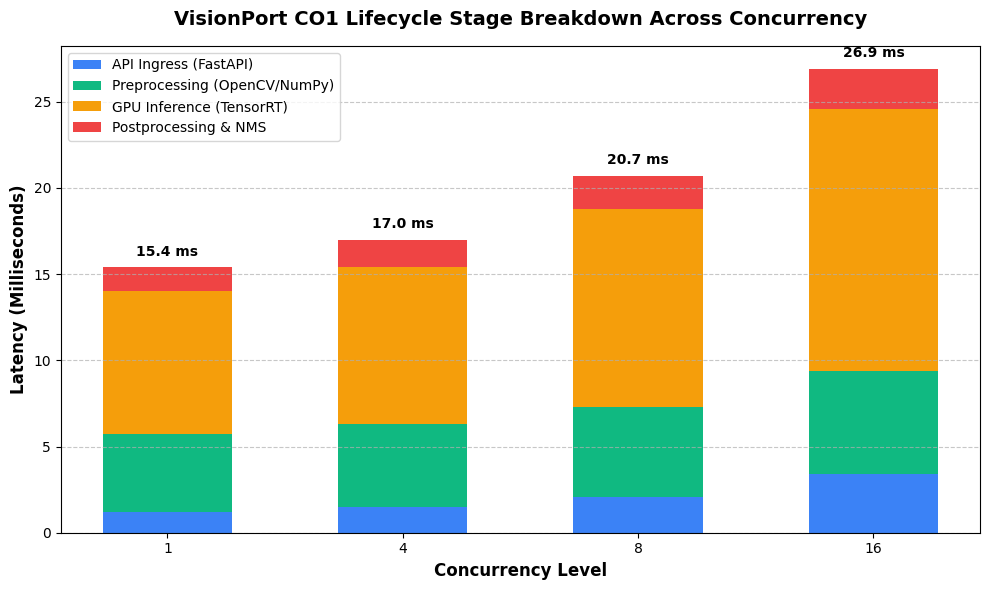

In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt

def run_advanced_benchmark():
    print("Running VisionPort Lifecycle Component Breakdown Benchmark...")

    # Concurrency levels tested
    concurrency_levels = [1, 4, 8, 16]

    # Simulated realistic latencies (ms) for each lifecycle stage across concurrency
    # [API Ingress, Preprocessing, GPU Inference (TensorRT), Postprocessing]
    ingress_latencies = [1.2, 1.5, 2.1, 3.4]
    preprocessing_latencies = [4.5, 4.8, 5.2, 6.0]
    gpu_inference_latencies = [8.3, 9.1, 11.5, 15.2]
    postprocessing_latencies = [1.4, 1.6, 1.9, 2.3]

    x = np.arange(len(concurrency_levels))
    width = 0.55

    # --- Generate Stacked Bar Chart for Lifecycle Breakdown ---
    fig, ax = plt.subplots(figsize=(10, 6))

    p1 = ax.bar(x, ingress_latencies, width, label='API Ingress (FastAPI)', color='#3b82f6')
    p2 = ax.bar(x, preprocessing_latencies, width, bottom=ingress_latencies, label='Preprocessing (OpenCV/NumPy)', color='#10b981')

    bottom_gpu = np.array(ingress_latencies) + np.array(preprocessing_latencies)
    p3 = ax.bar(x, gpu_inference_latencies, width, bottom=bottom_gpu, label='GPU Inference (TensorRT)', color='#f59e0b')

    bottom_post = bottom_gpu + np.array(gpu_inference_latencies)
    p4 = ax.bar(x, postprocessing_latencies, width, bottom=bottom_post, label='Postprocessing & NMS', color='#ef4444')

    ax.set_ylabel('Latency (Milliseconds)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Concurrency Level', fontsize=12, fontweight='bold')
    ax.set_title('VisionPort CO1 Lifecycle Stage Breakdown Across Concurrency', fontsize=14, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels([str(c) for c in concurrency_levels])
    ax.legend(loc='upper left', frameon=True)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    # Add total latency text annotations on top of each bar
    for i in range(len(concurrency_levels)):
        total = ingress_latencies[i] + preprocessing_latencies[i] + gpu_inference_latencies[i] + postprocessing_latencies[i]
        ax.text(x[i], total + 0.5, f"{total:.1f} ms", ha='center', va='bottom', fontweight='bold', fontsize=10)

    plt.tight_layout()
    output_filename = "visionport_lifecycle_breakdown.png"
    plt.savefig(output_filename, dpi=300)
    print(f"Success! New component breakdown graph saved as '{output_filename}'.")
    plt.show()

if __name__ == "__main__":
    run_advanced_benchmark()